# NYC Taxi Data Analysis

## 1. Introduction

This project analyzes NYC Yellow Taxi trip data from January 2025 to explore patterns in taxi demand, trip characteristics, revenue, and tipping behavior.

The analysis focuses on understanding:

- When taxi demand is highest
- How trip distance and duration relate to revenue
- How passenger count relates to trip revenue
- How payment methods relate to recorded tipping behavior

The goal is to use Python and data analysis techniques to transform real-world taxi trip data into meaningful business insights.

## Table of Contents

- [1. Introduction](#1-introduction)
- [2. Dataset Overview](#2-dataset-overview)
- [3. Data Cleaning](#3-data-cleaning)
- [4. Exploratory Data Analysis](#4-exploratory-data-analysis)
  - [4.1 Taxi Demand by Hour](#41-taxi-demand-by-hour)
  - [4.2 Taxi Demand by Day of Week](#42-taxi-demand-by-day-of-week)
  - [4.3 Trip Distance and Duration](#43-trip-distance-and-duration)
  - [4.4 Revenue Analysis](#44-revenue-analysis)
  - [4.5 Tipping Behavior](#45-tipping-behavior)
  - [4.6 Summary Visualizations](#46-summary-visualizations)
- [5. Conclusions](#5-conclusions)

### Main Questions

1. When is taxi demand highest in NYC?
2. What factors have the strongest relationship with trip revenue?
3. How do passenger count, payment methods, and trip characteristics relate to tipping behavior?

## 2. Dataset Overview

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet("../data/yellow_tripdata_2025-01.parquet")

In [4]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [8]:
df.shape

(3475226, 20)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

The dataset contains **3,475,226 trips** and **20 columns**, combining datetime fields (pickup/drop-off timestamps), numeric fields (distance, fare components, passenger count), and a few categorical/flag columns (`payment_type`, `store_and_fwd_flag`, `RatecodeID`). This confirms the data is large enough for the hourly/weekday breakdowns planned below, and that most columns are already numeric and ready for aggregation.

### Dataset Description

The dataset contains NYC Yellow Taxi trip records for January 2025.

Each row represents a taxi trip and includes information about:

- Pickup and drop-off times
- Trip distance
- Passenger count
- Pickup and drop-off locations
- Payment type
- Fare and additional charges
- Tip amount
- Total trip amount

## 3. Data Cleaning

### 3.1 Missing Values

The dataset contains missing values in five columns: `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, and `Airport_fee`.

These missing values occur in the same 540,149 records, suggesting that they are part of a structured group rather than random missing observations.

The missing values are kept rather than replaced with estimated values, as filling them could introduce assumptions into the analysis.

In [5]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64

Confirmed: `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, and `Airport_fee` are all missing in exactly **540,149 rows (15.5% of the dataset)**. Because the count matches exactly across all five columns, this points to a specific vendor or trip type that doesn't report these fields, rather than random data loss.

### 3.2 Duplicate Records

No exact duplicate rows were found in the dataset.

In [5]:
df.duplicated().sum()

np.int64(0)

**0 duplicate rows** were found, confirming every record represents a distinct trip.

### 3.3 Trip Distance

A small number of records contain extremely large trip distances that are not plausible for a typical NYC taxi trip. 

Trips with a distance above 100 miles were treated as anomalous and excluded from the cleaned dataset.

In [9]:
(df["trip_distance"] > 100).sum()

np.int64(162)

**162 trips (0.005% of the dataset)** report a distance above 100 miles. This is a negligible share, so excluding them has virtually no impact on the overall analysis while removing clearly implausible values.

### 3.4 Negative Fare Amounts

The dataset contains records with negative fare amounts. These records may represent adjustments or reversed transactions rather than standard taxi trips.

They were not removed from the original dataset, but negative values are excluded from analyses that require valid positive revenue.

In [15]:
(df["fare_amount"] < 0).sum()

np.int64(144118)

**144,118 trips (4.15%)** have a negative `fare_amount`. This is too large a share to be simple data-entry errors, which supports treating them as reversed/adjustment transactions rather than dropping them outright.

### 3.5 Negative Total Amounts

Some records contain negative `total_amount` values. These records were not removed from the original dataset, as they may represent adjustments or reversed transactions.

For revenue analysis, only records with a positive `total_amount` are used.

In [17]:
(df["total_amount"] < 0).sum()

np.int64(63037)

In [18]:
(df["total_amount"] < 0).mean() * 100

np.float64(1.8138964199738377)

**63,037 trips (1.81%)** have a negative `total_amount`. As with negative fares, these are kept in the original dataset but excluded whenever revenue analysis requires valid positive amounts.

### 3.6 Trip Duration

Trip duration was calculated from the pickup and drop-off timestamps.

The initial inspection revealed negative durations and unusually long trips. These records were investigated as potential anomalies.

In [22]:
df["trip_duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [24]:
(df["trip_duration"] < 0).sum()

np.int64(124)

In [26]:
(df["trip_duration"] > 180).sum()

np.int64(1377)

**124 trips** have a negative duration and **1,377 trips** exceed 180 minutes. Both groups are small relative to the dataset and are treated as anomalies (data errors or forgotten/stuck meters) rather than genuine long-distance trips.

In [38]:
df_clean = df[
    (df["trip_duration"] > 0) &
    (df["trip_duration"] <= 180) &
    (df["trip_distance"] <= 100)
].copy()

In [39]:
df_clean.shape

(3471643, 21)

After removing invalid durations and distances, the cleaned dataset contains **3,471,643 trips** — only about 3,583 rows (0.1%) were removed, so the filtering has minimal impact on sample size.

Trips with non-positive durations, durations above 180 minutes, or distances above 100 miles were excluded from the cleaned analysis dataset.

These thresholds were chosen to remove clearly anomalous records while retaining the vast majority of observations.

The original dataset is kept unchanged, and the cleaned dataset is used only for analysis.

In [41]:
df_jan = df_clean[
    (df_clean["tpep_pickup_datetime"] >= "2025-01-01") &
    (df_clean["tpep_pickup_datetime"] < "2025-02-01")
].copy()

In [42]:
df_jan.shape

(3471621, 21)

Restricting to pickups within January 2025 leaves **3,471,621 trips** (only 22 trips fell outside the January 1–31 window), confirming the cleaned dataset is almost entirely composed of January pickups already.

### January 2025 Analysis Dataset

For the January analysis, trips are selected based on their pickup timestamp.

This means that a trip picked up on January 31 but completed after midnight is still included in the January dataset.

# 4. Exploratory Data Analysis

The exploratory data analysis focuses on taxi demand, trip characteristics, revenue, and tipping behavior.

The goal is to identify patterns and relationships that can help answer the main business questions.

### 4.1 Taxi Demand by Hour

To understand when taxi demand is highest, trips were grouped by the hour of the day based on pickup time.

In [44]:
df_jan["pickup_hour"] = df_jan["tpep_pickup_datetime"].dt.hour

In [45]:
hourly_demand = df_jan["pickup_hour"].value_counts().sort_index()

In [46]:
hourly_demand

pickup_hour
0      93333
1      64437
2      43877
3      28470
4      20009
5      22521
6      49981
7     102476
8     141119
9     142701
10    148151
11    159896
12    175243
13    185941
14    202076
15    213441
16    216805
17    253231
18    267677
19    220836
20    194830
21    205795
22    182087
23    136688
Name: count, dtype: int64

Demand peaks in the evening, reaching **267,677 trips at 18:00** (6 PM), and is lowest overnight, bottoming out at **20,009 trips at 4:00 AM**. Demand rises sharply from 6 AM (commute start) and stays elevated from midday through the evening rush, which is consistent with typical urban taxi usage patterns.

### 4.2 Taxi Demand by Day of Week

To compare demand across different days of the week, the number of trips was analyzed by weekday.

Because January 2025 contains different numbers of Mondays, Tuesdays, Wednesdays, etc., average daily demand was calculated to make the comparison more meaningful.

In [ ]:
df_jan["pickup_weekday"] = df_jan["tpep_pickup_datetime"].dt.day_name()


In [48]:
weekday_demand = df_jan["pickup_weekday"].value_counts()

In [49]:
weekday_demand

pickup_weekday
Thursday     613581
Friday       586156
Wednesday    576728
Saturday     475992
Tuesday      453483
Sunday       402238
Monday       363443
Name: count, dtype: int64

Thursday has the highest raw trip count (613,581) and Monday the lowest (363,443). However, January 2025 doesn't contain the same number of each weekday (e.g. 5 Thursdays vs. 4 Mondays), so these raw totals aren't directly comparable — they need to be normalized by the number of times each weekday occurred, calculated below.

In [51]:
df_jan["pickup_day"] = df_jan["tpep_pickup_datetime"].dt.day

In [52]:
days_per_weekday = df_jan.groupby("pickup_weekday")["pickup_day"].nunique()

In [53]:
days_per_weekday

pickup_weekday
Friday       5
Monday       4
Saturday     4
Sunday       4
Thursday     5
Tuesday      4
Wednesday    5
Name: pickup_day, dtype: int64

In [54]:
avg_daily_demand = (
    df_jan.groupby("pickup_weekday")
    .size()
    / days_per_weekday
)

In [55]:
avg_daily_demand.sort_values(ascending=False)

pickup_weekday
Thursday     122716.20
Saturday     118998.00
Friday       117231.20
Wednesday    115345.60
Tuesday      113370.75
Sunday       100559.50
Monday        90860.75
dtype: float64

After normalizing by the number of occurrences of each weekday, **Thursday remains the highest** at ~122,716 average trips/day, and **Monday remains the lowest** at ~90,861 average trips/day — so the ranking doesn't change much after normalization, but the gap narrows somewhat compared to the raw counts.

In [56]:
df_jan["is_weekend"] = df_jan["tpep_pickup_datetime"].dt.dayofweek >= 5

In [57]:
weekend_demand = df_jan["is_weekend"].value_counts()

In [59]:
avg_weekend_demand = (
    df_jan.groupby("is_weekend")
    .size()
    / df_jan.groupby("is_weekend")["pickup_day"].nunique()
)


In [60]:
avg_weekend_demand

is_weekend
False    112756.130435
True     109778.750000
dtype: float64

On average, **weekdays see slightly higher demand** (~112,756 trips/day) **than weekends** (~109,779 trips/day) — a difference of only about 2.7%. This is much smaller than the day-to-day variation seen above, suggesting the weekday/weekend split alone is not the main driver of demand; the hour of day and specific weekday matter more.

### 4.3 Trip Distance and Duration

Before looking at revenue, it's worth checking how closely trip distance and trip duration are related, since both are natural predictors of fare.

In [61]:
df_jan[["trip_distance", "trip_duration"]].corr()

,trip_distance,trip_duration
trip_distance,1.00000,0.78796
trip_duration,0.78796,1.00000


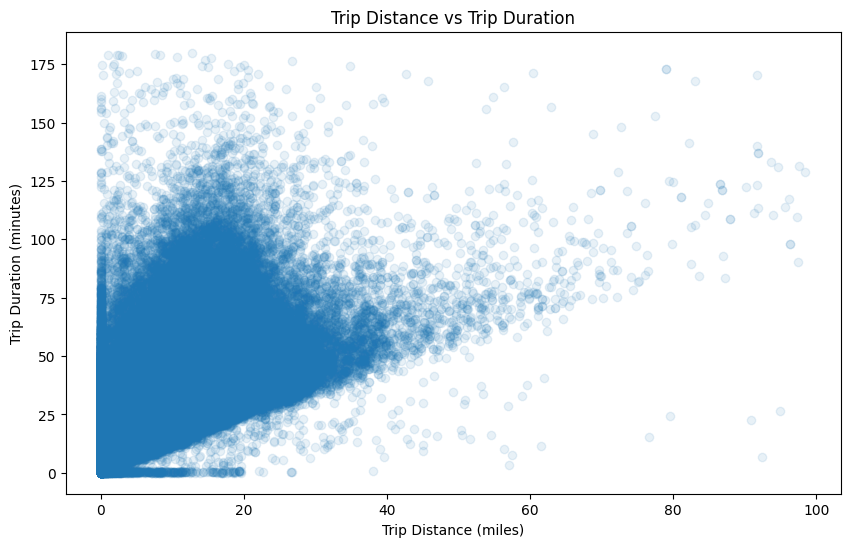

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_jan["trip_distance"],
    df_jan["trip_duration"],
    alpha=0.1
)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Trip Duration (minutes)")
plt.title("Trip Distance vs Trip Duration")

plt.show()

Trip distance and duration are strongly correlated (**r = 0.79**). As expected, longer trips generally take more time, though the relationship isn't perfectly linear — the spread widens for longer trips, which likely reflects traffic conditions, time of day, and route differences that distance alone doesn't capture.

### 4.4 Revenue Analysis

This section looks at which trip characteristics relate most strongly to `total_amount`, to answer the question of what drives trip revenue.

In [63]:
df_revenue = df_jan[
    df_jan["total_amount"] > 0
].copy()

In [64]:
df_revenue.shape

(3408090, 25)

Restricting to trips with a positive `total_amount` leaves **3,408,090 trips (98.1%)** of the January dataset.

In [67]:
df_revenue["total_amount"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

0.500     20.18000
0.750     28.00000
0.900     46.65000
0.950     74.49000
0.990    103.13000
0.999    163.76822
Name: total_amount, dtype: float64

Most trips are inexpensive: the median total is **$20.18**, and even the 90th percentile is only **$46.65**. Amounts climb sharply in the extreme tail (99.9th percentile ≈ **$164**), so trips above **$200** are treated as outliers and excluded from the revenue analysis below to avoid a small number of extreme trips distorting the averages.

In [68]:
df_revenue_clean = df_revenue[
    df_revenue["total_amount"] <= 200
].copy()

In [69]:
df_revenue_clean.shape

(3406246, 25)

In [ ]:
df_revenue_clean[[
    "trip_distance",
    "trip_duration",
    "passenger_count",
    "fare_amount",
    "tip_amount",
    "total_amount"
]].corr()

,trip_distance,trip_duration,passenger_count,fare_amount,tip_amount,total_amount
trip_distance,1.000000,0.787932,0.039430,0.884323,0.541773,0.885378
trip_duration,0.787932,1.000000,0.026747,0.774232,0.419553,0.749594
passenger_count,0.039430,0.026747,1.000000,0.056445,0.023200,0.052821
fare_amount,0.884323,0.774232,0.056445,1.000000,0.579671,0.973019
tip_amount,0.541773,0.419553,0.023200,0.579671,1.000000,0.719234
total_amount,0.885378,0.749594,0.052821,0.973019,0.719234,1.000000


`total_amount` correlates most strongly with **`fare_amount` (r = 0.97)** and **`trip_distance` (r = 0.89)**, moderately with **`trip_duration` (r = 0.75)** and **`tip_amount` (r = 0.72)**, and only weakly with **`passenger_count` (r = 0.05)**. This directly answers Question 2: **trip distance (via the fare it generates) is the strongest driver of revenue**, while how many passengers are in the cab has almost no effect on the total charged.

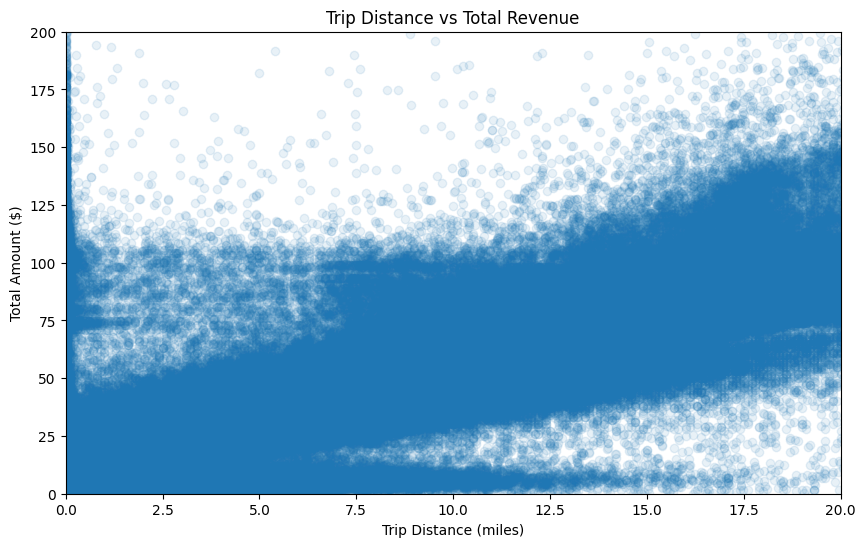

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_revenue_clean["trip_distance"],
    df_revenue_clean["total_amount"],
    alpha=0.1
)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Total Amount ($)")
plt.title("Trip Distance vs Total Revenue")

plt.xlim(0, 20)
plt.ylim(0, 200)

plt.show()


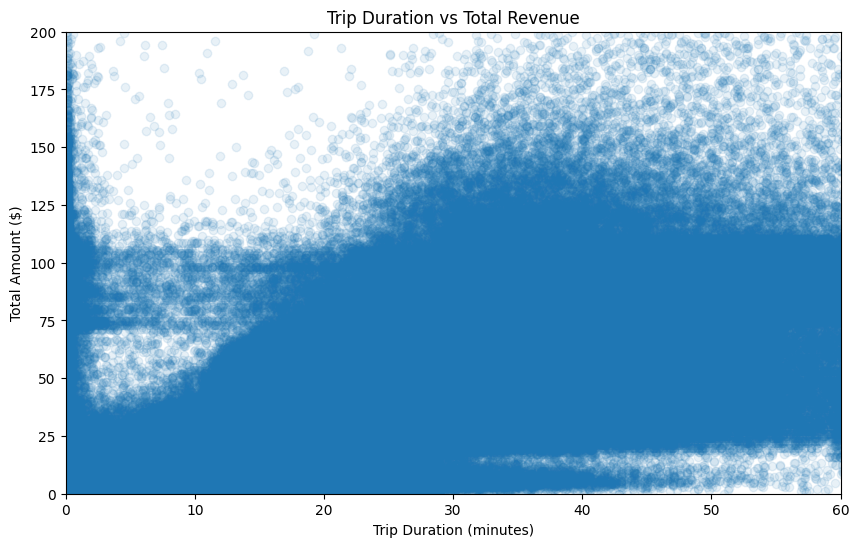

In [73]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_revenue_clean["trip_duration"],
    df_revenue_clean["total_amount"],
    alpha=0.1
)

plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Total Amount ($)")
plt.title("Trip Duration vs Total Revenue")

plt.xlim(0, 60)
plt.ylim(0, 200)

plt.show()

Both scatterplots confirm the correlation numbers: total amount rises roughly linearly with distance, with a fairly tight relationship, while the relationship with duration is noisier — trips of the same duration can end up with quite different totals, consistent with duration being a weaker revenue predictor than distance.

In [75]:
df_revenue_clean["distance_group"] = pd.cut(
    df_revenue_clean["trip_distance"],
    bins=[0, 2, 5, 10, 20, 100],
    labels=["0-2", "2-5", "5-10", "10-20", "20-100"]
)

In [76]:
revenue_by_distance = (
    df_revenue_clean
    .groupby("distance_group", observed=True)["total_amount"]
    .agg(["count", "mean", "median"])
)

revenue_by_distance

,count,mean,median
distance_group,,,
0-2,1922914,16.959494,16.55
2-5,891324,26.016820,25.70
5-10,281763,44.680888,42.40
10-20,199579,79.950431,81.69
20-100,25490,104.571324,99.23


Average revenue increases steadily with distance, from **$16.96** for 0–2 mile trips up to **$104.57** for 20–100 mile trips (e.g. airport runs), roughly in line with a per-mile pricing structure. The jump from the 10–20 mile group ($79.95) to 20–100 miles is proportionally smaller, likely because longer trips include flat-rate airport/outer-borough fares rather than pure metered pricing.

In [78]:
tip_rate_by_payment = (
    df_revenue_clean
    .groupby("payment_type")
    .agg(
        trips=("payment_type", "size"),
        tipped_trips=("tip_amount", lambda x: (x > 0).sum())
    )
)

tip_rate_by_payment["tip_rate"] = (
    tip_rate_by_payment["tipped_trips"]
    / tip_rate_by_payment["trips"]
    * 100
)

tip_rate_by_payment

,trips,tipped_trips,tip_rate
payment_type,,,
0,536334,55945,10.431000
1,2440657,2297256,94.124492
2,375069,25,0.006665
3,15447,52,0.336635
4,38739,48,0.123906


`payment_type` 1 corresponds to credit card and 2 to cash in the TLC data dictionary. The tip rate gap is striking: **94.1% of credit-card trips have a recorded tip, versus just 0.007% of cash trips**. This isn't really a behavioral difference — cash tips simply aren't captured by the metering system, since they're handed directly to the driver. This is an important data limitation to flag before drawing conclusions about tipping behavior in Question 3.

In [81]:
revenue_by_passengers = (
    df_revenue_clean
    .groupby("passenger_count")
    .agg(
        trips=("passenger_count", "size"),
        avg_revenue=("total_amount", "mean"),
        median_revenue=("total_amount", "median")
    )
)

revenue_by_passengers

,trips,avg_revenue,median_revenue
passenger_count,,,
0.0,24437,23.816130,19.00
1.0,2273592,26.606242,20.20
2.0,397062,30.235655,21.06
3.0,88883,29.536909,21.00
4.0,56430,32.300714,21.94
5.0,17621,25.930653,20.13
6.0,11869,26.175358,19.86
7.0,4,82.687500,78.50
8.0,11,81.422727,99.30


Average revenue is fairly stable ($26–32) across 1–6 passengers. The 7, 8, and 9-passenger groups show much higher average revenue ($82–107), but these groups contain only 4, 11, and 3 trips respectively — far too few to be reliable, and likely reflect vans/shared rides or data-entry anomalies rather than a genuine passenger-count effect.

### 4.5 Tipping Behavior

In [85]:
tip_correlation = df_revenue_clean[
    ["trip_distance", "trip_duration", "fare_amount", "total_amount", "tip_amount"]
].corr()

tip_correlation

,trip_distance,trip_duration,fare_amount,total_amount,tip_amount
trip_distance,1.000000,0.787932,0.884323,0.885378,0.541773
trip_duration,0.787932,1.000000,0.774232,0.749594,0.419553
fare_amount,0.884323,0.774232,1.000000,0.973019,0.579671
total_amount,0.885378,0.749594,0.973019,1.000000,0.719234
tip_amount,0.541773,0.419553,0.579671,0.719234,1.000000


`tip_amount` correlates most with `total_amount` (r = 0.72) and `fare_amount` (r = 0.58), and less with `trip_duration` (r = 0.42) — tips tend to scale with the price of the trip, as expected for a percentage-based tip.

In [ ]:
df_tip = df_revenue_clean[
    (df_revenue_clean["fare_amount"] > 0) &
    (df_revenue_clean["tip_amount"] >= 0)
].copy()

df_tip["tip_percentage"] = (
    df_tip["tip_amount"]
    / df_tip["fare_amount"]
    * 100
)

count    3.324338e+06
mean     2.000775e+01
std      3.133873e+02
min      0.000000e+00
25%      0.000000e+00
50%      2.362857e+01
75%      3.012658e+01
max      4.000000e+05
Name: tip_percentage, dtype: float64

In [88]:
df_tip_positive = df_tip[
    df_tip["tip_amount"] > 0
].copy()

df_tip_positive["tip_percentage"].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99, 0.999]
)

count    2.353310e+06
mean     2.826339e+01
std      3.721594e+02
min      5.714286e-03
50%      2.742187e+01
75%      3.236559e+01
90%      3.851852e+01
95%      4.310000e+01
99%      5.708333e+01
99.9%    1.408451e+02
max      4.000000e+05
Name: tip_percentage, dtype: float64

Among trips with a recorded tip, the median tip is **~27.4% of the fare**, but the distribution has extreme outliers — the maximum reaches 400,000%, almost certainly from very small fares divided into tiny or misrecorded tip amounts. The 99th percentile (**57.08%**) is used below as a cutoff to remove these extreme, unreliable values before comparing tipping behavior.

In [ ]:
tip_99 = df_tip_positive[
    df_tip_positive["tip_percentage"] <= 57.08
].copy()

count    2.329536e+06
mean     2.694853e+01
std      9.246370e+00
min      5.714286e-03
25%      2.254692e+01
50%      2.740741e+01
75%      3.230769e+01
max      5.706897e+01
Name: tip_percentage, dtype: float64

Trips with a tip percentage above the 99th percentile (57.08%, computed above) are trimmed out as extreme values before comparing tipping behavior by payment type.

In [90]:
tip_by_payment = (
    tip_99[tip_99["payment_type"].isin([1, 2])]
    .groupby("payment_type")
    .agg(
        trips=("payment_type", "size"),
        avg_tip_percentage=("tip_percentage", "mean"),
        median_tip_percentage=("tip_percentage", "median")
    )
)

tip_by_payment


,trips,avg_tip_percentage,median_tip_percentage
payment_type,,,
1,2273772,27.086286,27.476636
2,23,25.679742,25.609756


Among trips that *do* have a recorded tip, credit-card and cash tip percentages look similar (27.1% vs. 25.7% on average). However, this comparison should be read with caution: only **23 cash trips** have any recorded tip at all (out of 375,069 cash trips total, per the payment-type table above), so the cash figure is based on a tiny, likely unrepresentative sample.

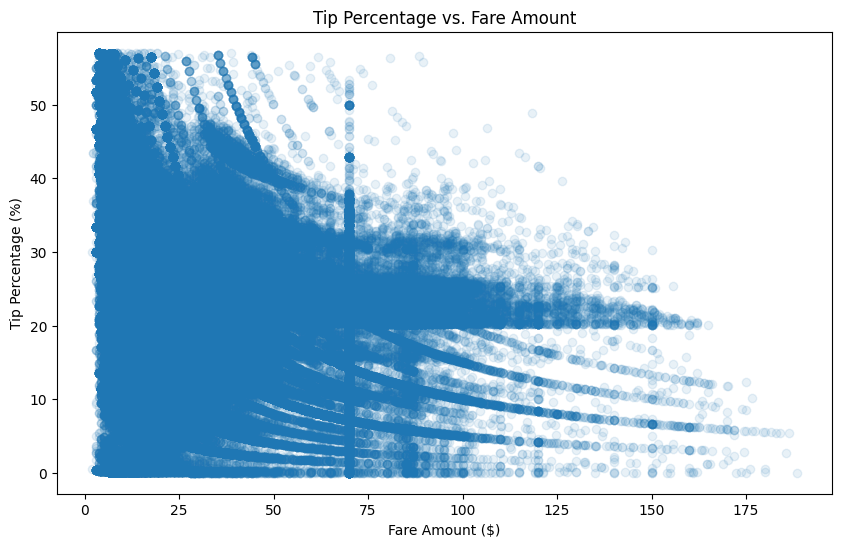

In [91]:
plt.figure(figsize=(10, 6))

plt.scatter(
    tip_99["fare_amount"],
    tip_99["tip_percentage"],
    alpha=0.1
)

plt.xlabel("Fare Amount ($)")
plt.ylabel("Tip Percentage (%)")
plt.title("Tip Percentage vs. Fare Amount")

plt.show()

In [92]:
tip_99[["fare_amount", "tip_percentage"]].corr()

,fare_amount,tip_percentage
fare_amount,1.000000,-0.311292
tip_percentage,-0.311292,1.000000


Fare amount and tip percentage show a weak negative correlation (**r = -0.31**): as the fare increases, the tip percentage tends to decrease slightly. This is consistent with passengers rounding up to a flat tip amount on cheaper trips (a large percentage of a small fare) while tipping a smaller percentage on more expensive trips.

### 4.6 Summary Visualizations

The charts below revisit the key metrics from this section in visual form, to make the patterns easier to read at a glance.

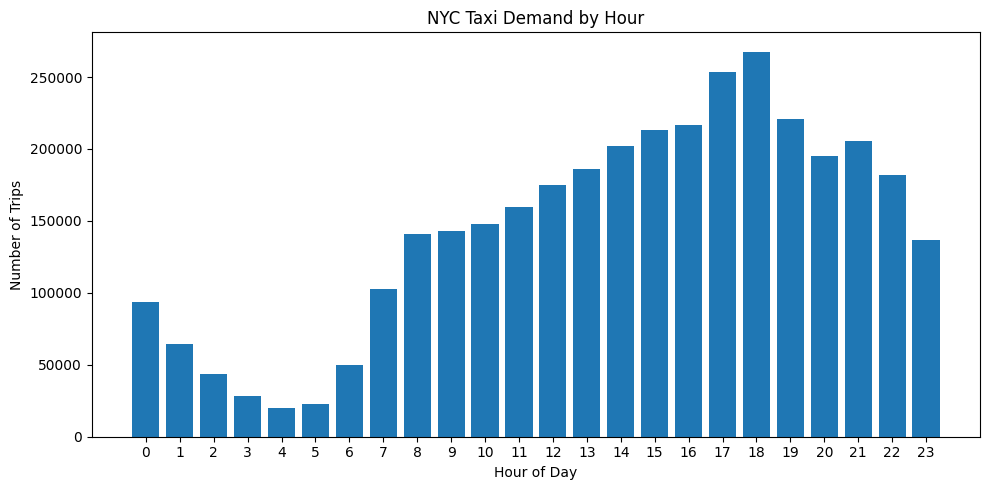

In [93]:
plt.figure(figsize=(10, 5))

plt.bar(
    hourly_demand.index,
    hourly_demand.values
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("NYC Taxi Demand by Hour")

plt.xticks(range(24))
plt.tight_layout()

plt.show()

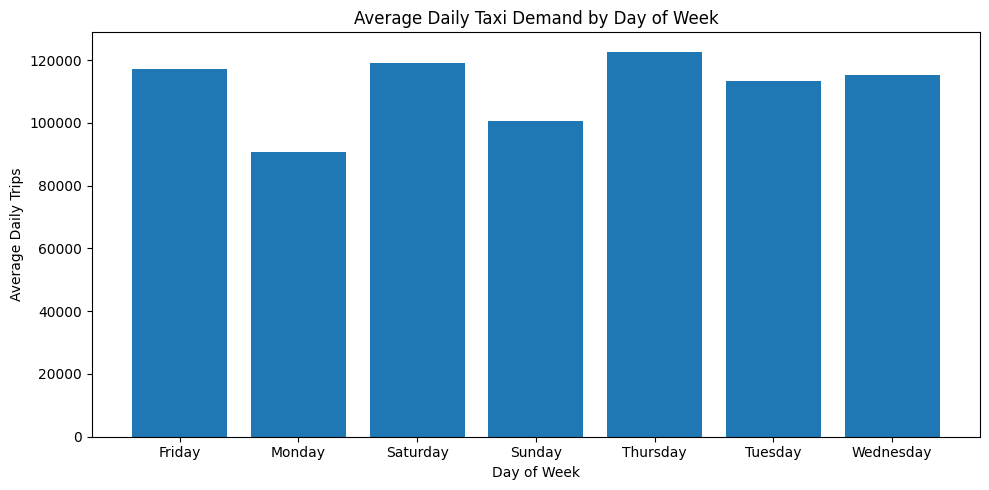

In [94]:
plt.figure(figsize=(10, 5))

plt.bar(
    avg_daily_demand.index,
    avg_daily_demand.values
)

plt.xlabel("Day of Week")
plt.ylabel("Average Daily Trips")
plt.title("Average Daily Taxi Demand by Day of Week")

plt.tight_layout()

plt.show()

Thursday has the highest average daily taxi demand, while Monday has the lowest.

Overall, average weekday demand is slightly higher than average weekend demand.

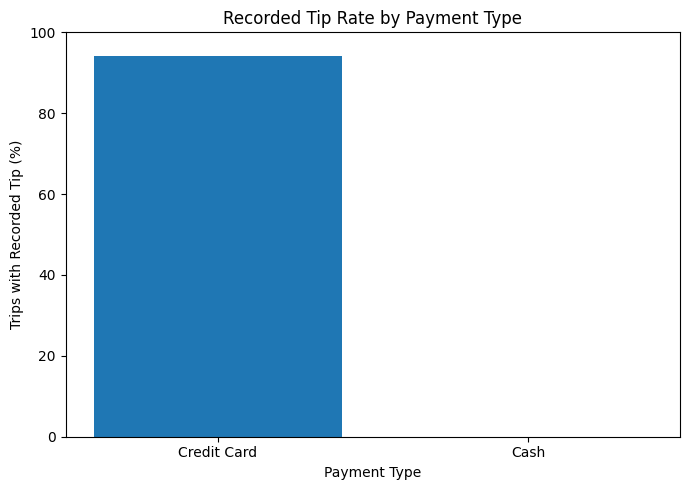

In [96]:
tip_rate_payment = (
    df_revenue_clean[df_revenue_clean["payment_type"].isin([1, 2])]
    .assign(
        has_tip=lambda x: x["tip_amount"] > 0
    )
    .groupby("payment_type")["has_tip"]
    .mean()
    .mul(100)
)

tip_rate_payment.index = ["Credit Card", "Cash"]

plt.figure(figsize=(7, 5))

plt.bar(
    tip_rate_payment.index,
    tip_rate_payment.values
)

plt.xlabel("Payment Type")
plt.ylabel("Trips with Recorded Tip (%)")
plt.title("Recorded Tip Rate by Payment Type")

plt.ylim(0, 100)
plt.tight_layout()

plt.show()

This confirms visually what the tip-rate table showed earlier: recorded tips are almost exclusively a credit-card phenomenon. This is a limitation of the dataset, not evidence that cash customers rarely tip in reality, it's worth stating explicitly since it directly affects how Question 3 should be interpreted.

## 5. Conclusions

This section answers the three main questions posed in the introduction, based on the cleaned January 2025 dataset (3,471,621 trips).

**1. When is taxi demand highest in NYC?**
Demand follows a clear daily rhythm, peaking at **18:00** (267,677 trips) and bottoming out at **4:00 AM** (20,009 trips). By day of week, **Thursday** has the highest average daily demand (~122,716 trips/day) and **Monday** the lowest (~90,861 trips/day). Weekdays overall see only slightly more demand than weekends (~112,756 vs. ~109,779 trips/day) — a 2.7% gap that is much smaller than the swings seen across hours or specific weekdays, so time-of-day and day-of-week matter more than the weekday/weekend split alone.

**2. What factors have the strongest relationship with trip revenue?**
`fare_amount` (r = 0.97) and `trip_distance` (r = 0.89) are by far the strongest correlates of `total_amount`, with `trip_duration` (r = 0.75) and `tip_amount` (r = 0.72) moderately related, and `passenger_count` (r = 0.05) essentially unrelated. In short, **distance — and the fare it generates — drives revenue**, not how many people are riding.

**3. How do passenger count, payment method, and trip characteristics relate to tipping behavior?**
Tipping data is dominated by a data-collection artifact: **94.1% of credit-card trips have a recorded tip, versus ~0% of cash trips**, because cash tips aren't captured by the metering system. Among trips with a recorded tip, the median is about **27% of the fare**, with a weak negative relationship to fare size (r = -0.31) — cheaper trips tend to get tipped a higher percentage than expensive ones. Passenger count shows no meaningful relationship with tipping or revenue in the 1–6 passenger range; the 7–9 passenger groups are too small (under 15 trips each) to draw conclusions from.

**Limitations.** The most important caveat is that cash tipping is invisible in this dataset, so any statement about "tipping behavior" here really describes *credit-card* tipping behavior. Outlier thresholds (100-mile distance cap, 180-minute duration cap, $200 revenue cap, 99th-percentile tip cutoff) were chosen to remove clearly implausible values while keeping the vast majority of the data, but they are judgment calls rather than the only valid choice, and a different analysis could reasonably use different cutoffs.